# Module 6 · Branching processes: growth and extinction
**Applied Stochastic Processes: Modeling, Simulation, and AI**

Practical question: **Can a population have a growing mean and still have a substantial chance of disappearing?**

Guided work: about 45–55 minutes. Exercises: about 25–35 minutes. This is **Concept Lab 3, Part B (week 6)**. Submit it together with Module 5, Part A, as one lab; continue the existing course project.

Build a Galton–Watson model, compute finite-horizon and eventual extinction, separate parameter uncertainty from process randomness, and test whether the bike-sharing observations support a branching interpretation.

[Course home](../index.html) · [Interactive lesson](../modules/module06.html) · [Project guide](../project-guide.html) · [Data provenance](../data/PROVENANCE.md)

Use **Restart Kernel and Run All** from the course root or `notebooks/`. No network, account, API key, or server is needed. Keep exercise answers in the four marked cells; the worked examples do not supply those answers.

## 1. Individuals, offspring, and generations
Let $Z_n$ be the number of individuals in generation $n$, starting from a nonnegative integer $Z_0=z$. Every individual produces a nonnegative integer number of offspring. Under the Galton–Watson assumptions, the offspring counts $\xi_{n,i}$ are independent across individuals and generations with a common distribution:

$$Z_{n+1}=\sum_{i=1}^{Z_n}\xi_{n,i}.$$

The empty sum is zero, so zero is **absorbing**. Individuals do not persist into the next generation in this definition: the next generation consists of their offspring. Immigration, capacity limits, changing reproduction, and dependence between individuals require extensions.

Here $\xi_{n,i}\sim\operatorname{Poisson}(m)$. Sums of independent Poisson variables give

$$Z_{n+1}\mid Z_n\sim\operatorname{Poisson}(mZ_n).$$

This aggregate transition simulates the population exactly under the assumptions without constructing each family tree. The simulated population is not observed bike demand.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.stats import gamma as gamma_dist
from scipy.integrate import quad
from IPython.display import display

SEED = 6231
plt.rcParams.update({"figure.figsize": (10, 3.8), "font.size": 11})

In [2]:
def simulate_branching(m=1.2, z=1, horizon=20, replicas=2000, seed=SEED):
    if not (np.isfinite(m) and m >= 0 and int(z) == z and z >= 0):
        raise ValueError("Use a finite nonnegative mean and nonnegative integer initial population")
    if not (int(horizon) == horizon and horizon >= 0 and int(replicas) == replicas and replicas > 1):
        raise ValueError("Use a nonnegative integer horizon and at least two replicas")
    rng = np.random.default_rng(seed)
    paths = np.zeros((replicas, horizon+1), dtype=np.int64)
    paths[:, 0] = z
    for n in range(horizon):
        paths[:, n+1] = rng.poisson(m*paths[:, n])
    return paths

### Means and variances describe the entire population of paths
Conditional expectation and total variance yield

$$\mu_{n+1}=m\mu_n,\quad\mu_0=z,\qquad E[Z_n]=zm^n,$$
$$v_{n+1}=m^2v_n+m\mu_n,\quad v_0=0.$$

The second formula uses both $\operatorname{Var}(Z_{n+1}\mid Z_n)=mZ_n$ and $E[Z_{n+1}\mid Z_n]=mZ_n$. When $m=1$, $E[Z_n]=z$ and $\operatorname{Var}(Z_n)=zn$.

Classify the model as **subcritical** ($m<1$), **critical** ($m=1$), or **supercritical** ($m>1$). A mean that grows is not a promise that a particular path survives.

In [3]:
def branching_moments(m, z, horizon):
    means, variances = np.empty(horizon+1), np.zeros(horizon+1)
    means[0] = z
    for n in range(horizon):
        variances[n+1] = m*m*variances[n] + m*means[n]
        means[n+1] = m*means[n]
    return means, variances

M, Z0, H, REPLICAS = 1.2, 1, 20, 2000
paths = simulate_branching(M, Z0, H, REPLICAS)
theory_mean, theory_var = branching_moments(M, Z0, H)
sim_mean = paths.mean(axis=0)
mean_mcse = paths.std(axis=0, ddof=1)/np.sqrt(REPLICAS)

**Predict before plotting:** Will all paths resemble the expected value $1.2^n$? Which paths contribute to the mean after many generations?

Every replica, including every extinct path, contributes to the simulated mean. There is no population cap and no deletion of zeros. The mean's pointwise MCSE uses independent simulated replicas, not generations within one path. Approximate $\pm1.96$ MCSE bands quantify numerical error in the estimated mean, not prediction intervals for individual populations.

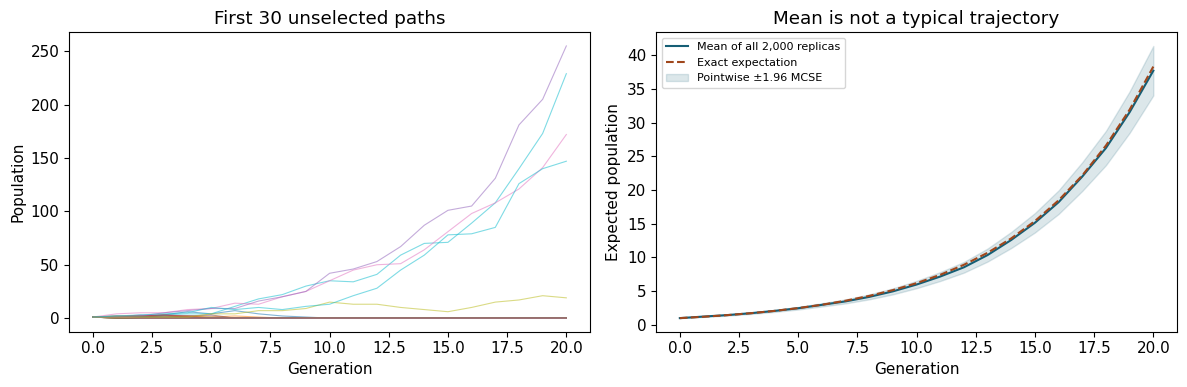

In [4]:
generations = np.arange(H+1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(generations, paths[:30].T, alpha=0.55, lw=0.8)
axes[0].set(xlabel="Generation", ylabel="Population", title="First 30 unselected paths")
axes[1].plot(generations, sim_mean, color="#155e75", label="Mean of all 2,000 replicas")
axes[1].plot(generations, theory_mean, color="#a0471c", ls="--", label="Exact expectation")
axes[1].fill_between(generations, sim_mean-1.96*mean_mcse, sim_mean+1.96*mean_mcse,
                     color="#155e75", alpha=0.15, label="Pointwise ±1.96 MCSE")
axes[1].set(xlabel="Generation", ylabel="Expected population", title="Mean is not a typical trajectory")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 2. Extinction by a deadline and eventual extinction
The offspring probability generating function is $f(s)=E[s^\xi]=e^{m(s-1)}$. Starting from one ancestor, let $q_n=P(Z_n=0\mid Z_0=1)$, which also equals the probability of extinction **by** generation $n$ because zero is absorbing. Conditioning on the first generation gives

$$q_0=0,\qquad q_{n+1}=f(q_n)=e^{m(q_n-1)}.$$

For $z$ independent ancestral lines, $P(Z_n=0\mid Z_0=z)=q_n^z$.

The increasing bounded sequence converges to the **smallest** fixed point $q=f(q)$ in $[0,1]$. Eventual extinction from $z$ ancestors has probability $q^z$. For the Poisson family, $q=1$ for $m\le1$, while $q<1$ for $m>1$.

Always distinguish $P(Z_H>0)=1-q_H^z$ from the probability $1-q^z$ of surviving forever. Simulations stopping at $H$ do not classify every surviving path's eventual fate.

In [5]:
def extinction_by(m, horizon, z=1):
    if not np.isfinite(z) or z < 0 or int(z) != z:
        raise ValueError("Use a nonnegative integer number of ancestors")
    m = np.asarray(m, dtype=float)
    if np.any(~np.isfinite(m)) or np.any(m < 0) or horizon < 0 or int(horizon) != horizon:
        raise ValueError("Use finite nonnegative means and an integer horizon")
    q = np.zeros_like(m)
    for _ in range(horizon):
        q = np.exp(m*(q-1))
    return q**z

q_curve = np.array([extinction_by(M, n, Z0) for n in generations])
empirical_extinction = (paths == 0).mean(axis=0)
extinction_mcse = np.sqrt(empirical_extinction*(1-empirical_extinction)/REPLICAS)

In [6]:
def eventual_extinction(m, z=1):
    if not np.isfinite(z) or z < 0 or int(z) != z:
        raise ValueError("Use a nonnegative integer number of ancestors")
    m = np.asarray(m, dtype=float)
    if np.any(~np.isfinite(m)) or np.any(m < 0):
        raise ValueError("Use finite nonnegative means")
    active = m > 1
    safe_m = np.where(active, m, 2.0)
    lower, upper = np.zeros_like(m), 1/safe_m
    for _ in range(70):
        middle = (lower+upper)/2
        residual = np.expm1(safe_m*(middle-1))-(middle-1)
        lower, upper = np.where(residual > 0, middle, lower), np.where(residual > 0, upper, middle)
    return np.where(active, (lower+upper)/2, 1.0)**z

The eventual-extinction solver returns the known value one for $m\le1$. For $m>1$, it bisects the smaller root inside $[0,1/m]$, avoiding the trivial root at one. Indeed, $e^{1-m}<1/m$ when $m>1$. This is an independent check on finite PGF iteration, not a claim that a long but finite simulation proves extinction.

At the default $m=1.2$, $q_{20}\approx0.682148$ and $q\approx0.686302$. Even a supercritical population with a rapidly increasing expected size has a large extinction probability from a single ancestor.

In [7]:
extinction_report = pd.Series({"Exact extinction by H": q_curve[-1],
    "Simulated extinction by H": empirical_extinction[-1], "Extinction estimate MCSE": extinction_mcse[-1],
    "Exact eventual extinction": eventual_extinction(M, Z0), "Exact mean at H": theory_mean[-1],
    "Simulated mean at H": sim_mean[-1], "Mean estimate MCSE": mean_mcse[-1],
    "Exact variance at H": theory_var[-1], "Simulated variance at H": paths[:, -1].var(ddof=1)})
display(extinction_report.to_frame("Default experiment").round(6))
assert np.all(paths[:, 1:][paths[:, :-1] == 0] == 0)
assert np.allclose(theory_mean, Z0*M**generations)
assert abs(sim_mean[-1]-theory_mean[-1]) < 6*np.sqrt(theory_var[-1]/REPLICAS)
assert abs(empirical_extinction[-1]-q_curve[-1]) < 6*np.sqrt(q_curve[-1]*(1-q_curve[-1])/REPLICAS)
assert np.all(np.diff(q_curve) >= 0) and q_curve[-1] <= eventual_extinction(M, Z0)

,Default experiment
Exact extinction by H,0.682148
Simulated extinction by H,0.686000
Extinction estimate MCSE,0.010378
Exact eventual extinction,0.686302
Exact mean at H,38.337600
Simulated mean at H,37.728500
Mean estimate MCSE,1.875116
Exact variance at H,7157.169840
Simulated variance at H,7032.116846


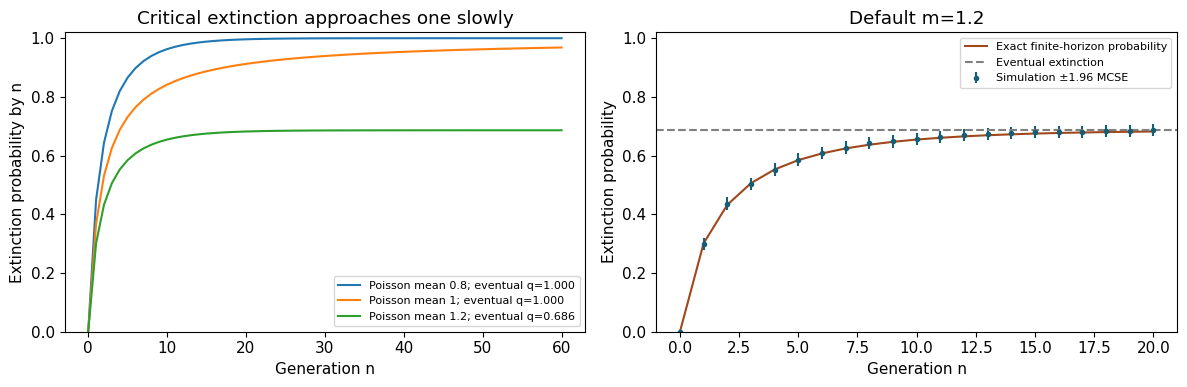

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for rate in [0.8, 1.0, 1.2]:
    curve = [extinction_by(rate, n) for n in range(61)]
    axes[0].plot(range(61), curve, label=f"Poisson mean {rate:g}; eventual q={eventual_extinction(rate):.3f}")
axes[0].set(xlabel="Generation n", ylabel="Extinction probability by n", ylim=(0, 1.02),
            title="Critical extinction approaches one slowly")
axes[1].plot(generations, q_curve, color="#a0471c", label="Exact finite-horizon probability")
axes[1].errorbar(generations, empirical_extinction, yerr=1.96*extinction_mcse,
                 fmt=".", color="#155e75", label="Simulation ±1.96 MCSE")
axes[1].axhline(eventual_extinction(M), color="gray", ls="--", label="Eventual extinction")
axes[1].set(xlabel="Generation n", ylabel="Extinction probability", ylim=(0, 1.02), title="Default m=1.2")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### The critical paradox: a constant expectation and almost-sure extinction
For Poisson(1) offspring and one ancestor, $E[Z_n]=1$ for every finite $n$, yet eventual extinction has probability one. At each finite generation, rare surviving populations carry the expectation:

$$E[Z_n\mid Z_n>0]=\frac{E[Z_n]}{P(Z_n>0)}=\frac1{1-q_n}.$$

This conditional mean grows as survival becomes rarer. We cannot exchange the limit and expectation without additional conditions. Reporting only surviving paths estimates a different quantity.

**Exception to remember:** if every individual deterministically has exactly one offspring, $\xi\equiv1$, then the mean is also one but $Z_n=z$ forever and extinction has probability zero. The critical extinction conclusion requires a nondegenerate offspring law; mean reproduction alone does not determine the distribution.

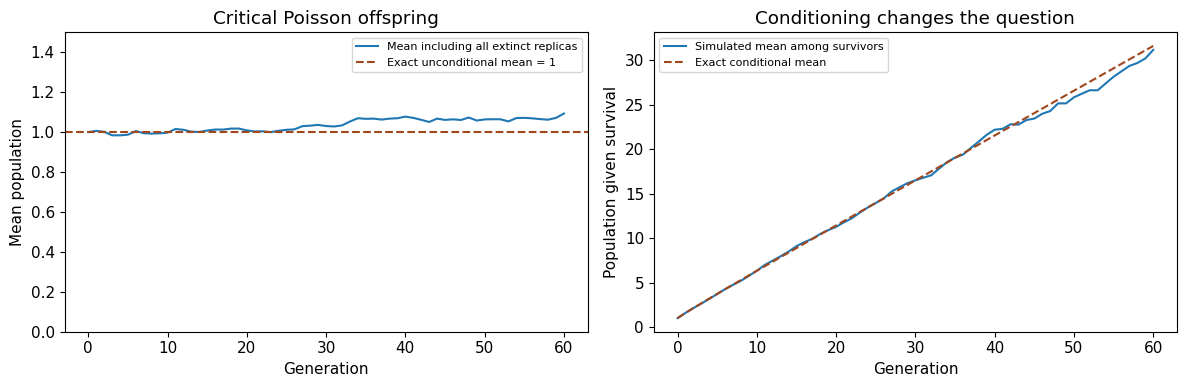

In [9]:
critical = simulate_branching(1.0, 1, 60, 10000, SEED+1)
critical_q = np.array([extinction_by(1.0, n) for n in range(61)])
critical_alive = (critical > 0).mean(axis=0)
critical_conditional = np.divide(critical.mean(axis=0), critical_alive,
    out=np.full(61, np.nan), where=critical_alive > 0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(61), critical.mean(axis=0), label="Mean including all extinct replicas")
axes[0].axhline(1, color="#a0471c", ls="--", label="Exact unconditional mean = 1")
axes[0].set(xlabel="Generation", ylabel="Mean population", ylim=(0, 1.5), title="Critical Poisson offspring")
axes[1].plot(range(61), critical_conditional, label="Simulated mean among survivors")
axes[1].plot(range(61), 1/(1-critical_q), color="#a0471c", ls="--", label="Exact conditional mean")
axes[1].set(xlabel="Generation", ylabel="Population given survival", title="Conditioning changes the question")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 3. Carry uncertainty in the offspring mean
This section uses a **clearly synthetic parent-level sample**, separate from the bike data: six parents with zero offspring, eight with one, four with two, and two with three. There are 20 parents and 22 offspring. These counts illustrate what a branching likelihood would need; they are not measured bike reproduction.

If $x_i\mid m\sim\operatorname{Poisson}(m)$ independently, then $L(m)\propto m^{\sum_i x_i}e^{-Km}$. Choose $m\sim\operatorname{Gamma}(\alpha_0=2,\beta_0=2)$ with **shape–rate** parameterization, density proportional to $m^{\alpha_0-1}e^{-\beta_0m}$. Thus

$$m\mid x\sim\operatorname{Gamma}(2+22,2+20)=\operatorname{Gamma}(24,22).$$

Its mean is $24/22\approx1.090909$. NumPy and SciPy use **scale** $1/\text{rate}$ when sampling. This conjugate posterior has direct independent draws, so MCMC is unnecessary. Module 5's lesson about checking numerical computation still applies.

In [10]:
offspring = np.repeat([0, 1, 2, 3], [6, 8, 4, 2])
PRIOR_SHAPE, PRIOR_RATE = 2, 2
POST_SHAPE = PRIOR_SHAPE + offspring.sum()
POST_RATE = PRIOR_RATE + len(offspring)
posterior_mean = POST_SHAPE/POST_RATE
posterior_ci = gamma_dist.ppf([0.025, 0.975], POST_SHAPE, scale=1/POST_RATE)
assert len(offspring) == 20 and offspring.sum() == 22
assert (POST_SHAPE, POST_RATE) == (24, 22)
display(pd.Series({"posterior mean": posterior_mean, "posterior SD": np.sqrt(POST_SHAPE)/POST_RATE,
    "credible lower": posterior_ci[0], "credible upper": posterior_ci[1],
    "posterior P(m <= 1)": gamma_dist.cdf(1, POST_SHAPE, scale=1/POST_RATE)}).round(6))

posterior mean         1.090909
posterior SD           0.222681
credible lower         0.698966
credible upper         1.568695
posterior P(m <= 1)    0.362576
dtype: float64

For a future population under one shared, unknown offspring mean, integrate **after** computing the conditional probability:

$$P(Z_H=0\mid x,Z_0=z)=E_{m\mid x}[q_H(m)^z],\qquad
P(\text{eventual extinction}\mid x,Z_0=z)=E_{m\mid x}[q(m)^z].$$

These are generally different from $q_H(E[m\mid x])^z$ and $q(E[m\mid x])^z$. There is no universal Jensen ordering for these functions over the whole posterior range.

For a posterior predictive path, draw one $m$ and **hold it fixed for the entire path**. Conditional on that value, all individuals and generations share the same Poisson law. Redrawing $m$ every generation creates a different model with a random environment. For multiple ancestors, integrate $q_H(m)^z$, not $(E[q_H(m)])^z$: uncertainty about the common parameter couples the ancestral lines marginally.

In [11]:
POST_DRAWS = 20000
posterior_m = np.random.default_rng(SEED+2).gamma(POST_SHAPE, 1/POST_RATE, POST_DRAWS)
conditional_finite = extinction_by(posterior_m, H, Z0)
conditional_eventual = eventual_extinction(posterior_m, Z0)
posterior_rows = []
for label, values, plugin in [("By generation 20", conditional_finite, extinction_by(posterior_mean, H, Z0)),
                              ("Eventually", conditional_eventual, eventual_extinction(posterior_mean, Z0))]:
    posterior_rows.append([label, values.mean(), values.std(ddof=1)/np.sqrt(POST_DRAWS), plugin,
                           *np.quantile(values, [0.025, 0.975])])
posterior_report = pd.DataFrame(posterior_rows, columns=["event", "integrated MC estimate", "MCSE",
    "posterior-mean plug-in", "probability credible lower", "probability credible upper"])
display(posterior_report.set_index("event").round(6))

,integrated MC estimate,MCSE,posterior-mean plug-in,probability credible lower,probability credible upper
event,,,,,
By generation 20,0.787862,0.001335,0.813372,0.374531,0.999662
Eventually,0.809094,0.001429,0.838097,0.374536,1.000000


In [12]:
posterior_density = lambda m: gamma_dist.pdf(m, POST_SHAPE, scale=1/POST_RATE)
exact_integrated_finite = quad(lambda m: extinction_by(m, H, Z0)*posterior_density(m), 0, np.inf)[0]
exact_integrated_eventual = (quad(posterior_density, 0, 1)[0] +
    quad(lambda m: eventual_extinction(m, Z0)*posterior_density(m), 1, np.inf)[0])
for exact, values in [(exact_integrated_finite, conditional_finite),
                      (exact_integrated_eventual, conditional_eventual)]:
    assert abs(values.mean()-exact) < 6*values.std(ddof=1)/np.sqrt(POST_DRAWS)
print("Independent quadrature checks:", exact_integrated_finite, exact_integrated_eventual)

Independent quadrature checks: 0.7865505330814601 0.8073565273716575


The integrated probabilities are approximately **0.786551 by generation 20** and **0.807357 eventually**. The plug-in probabilities are approximately **0.813372** and **0.838097**. These numbers refer to the synthetic offspring example, not to bike-sharing extinction.

The interval across conditional probabilities describes posterior parameter uncertainty in a model probability. It is not a prediction interval for a future binary extinction event. MCSE describes numerical error in the integrated expectation; more posterior draws can reduce it but do not add parent observations or make the posterior narrower.

Averaging the analytically computed $q_H(m)^z$ integrates out population randomness before Monte Carlo averaging. This is a conditional-expectation variance reduction, connecting Module 4 to Module 5's parameter uncertainty.

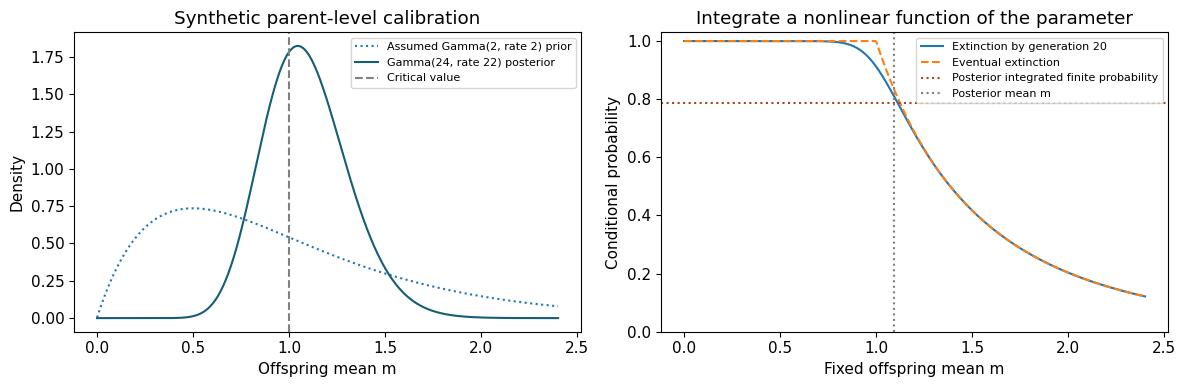

In [13]:
m_grid = np.linspace(0.001, 2.4, 500)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(m_grid, gamma_dist.pdf(m_grid, 2, scale=0.5), ls=":", label="Assumed Gamma(2, rate 2) prior")
axes[0].plot(m_grid, posterior_density(m_grid), color="#155e75", label="Gamma(24, rate 22) posterior")
axes[0].axvline(1, color="gray", ls="--", label="Critical value")
axes[0].set(xlabel="Offspring mean m", ylabel="Density", title="Synthetic parent-level calibration")
axes[1].plot(m_grid, extinction_by(m_grid, H), label="Extinction by generation 20")
axes[1].plot(m_grid, eventual_extinction(m_grid), ls="--", label="Eventual extinction")
axes[1].axhline(exact_integrated_finite, color="#a0471c", ls=":", label="Posterior integrated finite probability")
axes[1].axvline(posterior_mean, color="gray", ls=":", label="Posterior mean m")
axes[1].set(xlabel="Fixed offspring mean m", ylabel="Conditional probability", ylim=(0, 1.03),
            title="Integrate a nonlinear function of the parameter")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

In [14]:
predictive_rng = np.random.default_rng(SEED+3)
predictive_population = np.full(POST_DRAWS, Z0, dtype=np.int64)
for n in range(H):
    predictive_population = predictive_rng.poisson(posterior_m*predictive_population)
predictive_extinct = predictive_population == 0
predictive_fraction = predictive_extinct.mean()
predictive_mcse = np.sqrt(predictive_fraction*(1-predictive_fraction)/POST_DRAWS)
print(f"Fixed-m-per-path predictive simulation: {predictive_fraction:.6f}, MCSE {predictive_mcse:.6f}")
print(f"Conditional-probability MCSE: {conditional_finite.std(ddof=1)/np.sqrt(POST_DRAWS):.6f}")
assert abs(predictive_fraction-exact_integrated_finite) < 6*np.sqrt(
    exact_integrated_finite*(1-exact_integrated_finite)/POST_DRAWS)

Fixed-m-per-path predictive simulation: 0.789700, MCSE 0.002882
Conditional-probability MCSE: 0.001335


## 4. Does branching describe the bike-sharing observations?
The bundled UCI Bike Sharing observations (Fanaee-T, 2013; [DOI 10.24432/C5W894](https://doi.org/10.24432/C5W894), **CC BY 4.0**) record daily **completed rentals**. A rental today is not an identified parent of rentals tomorrow; the file does not record individual offspring, generations, unmet requests, or latent demand.

We can nevertheless challenge the provisional aggregate transition

$$X_{t+1}\mid X_t\sim\operatorname{Poisson}(mX_t).$$

Its conditional-likelihood MLE, using only adjacent pairs wholly inside January–August, is

$$\widehat m=\frac{\sum_{t=0}^{241}X_{t+1}}{\sum_{t=0}^{241}X_t}.$$

The formula follows by differentiating $\sum_t[X_{t+1}\log(mX_t)-mX_t-\log(X_{t+1}!)]$. It does **not** identify literal reproduction. Even a well-fitting aggregate transition would require a substantive argument for that interpretation. The same later September–December data are a **reused development holdout**, not an untouched final test.

In [15]:
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data/bike_daily_2011.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the downloaded course folder.")
csv_path = ROOT / "data/bike_daily_2011.csv"
source = json.loads((ROOT / "data/source_metadata.json").read_text())
assert hashlib.sha256(csv_path.read_bytes()).hexdigest() == source["sample_sha256"]
bike = pd.read_csv(csv_path, parse_dates=["dteday"])
assert bike["dteday"].tolist() == pd.date_range("2011-01-01", "2011-12-31").tolist()
assert bike["cnt"].notna().all() and bike["cnt"].gt(0).all()
assert np.equal(bike["cnt"], np.floor(bike["cnt"])).all()
train = bike.loc[bike["dteday"] < "2011-09-01"].copy()
x_train = train["cnt"].to_numpy()
assert len(train) == 243

In [16]:
numerator, denominator = x_train[1:].sum(), x_train[:-1].sum()
m_bike = numerator/denominator
assert (numerator, denominator) == (801699, 797626)
assert len(x_train[:-1]) == 242
later = bike.loc[bike["dteday"] >= "2011-09-01"].copy()
previous = bike["cnt"].shift(1).loc[later.index].to_numpy()
actual = later["cnt"].to_numpy()
branch_prediction = m_bike*previous
persistence_prediction = previous.copy()
assert len(later) == 122 and previous[0] == x_train[-1] == 5058
print(f"Training-only provisional aggregate m = {numerator}/{denominator} = {m_bike:.9f}")

Training-only provisional aggregate m = 801699/797626 = 1.005106403


For each later day, form a **one-day-ahead** conditional mean using the previous day's observed count and the fixed training estimate. September 1 uses the observed August 31 count. Subsequent days use their newly observed predecessor; this is rolling one-step evaluation, not an open-loop 122-day trajectory forecast. The August 31–September 1 pair is scored but was not used in fitting.

Compare with the persistence point baseline $\widehat X_{t+1}=X_t$. Report MAE and RMSE descriptively. Inspect Pearson residuals

$$r_{t+1}=\frac{X_{t+1}-\widehat mX_t}{\sqrt{\widehat mX_t}}.$$

Under the stated conditional Poisson model with known correct $m$, $E[r^2\mid X_t]=1$. The average squared residual on the later period is a diagnostic scale comparison, not a calibrated goodness-of-fit test: the parameter is fitted, dates may be dependent, and the period has been reused.

In [17]:
score_rows = []
for label, prediction in [("Provisional branching mean", branch_prediction),
                          ("Persistence", persistence_prediction)]:
    error = actual-prediction
    score_rows.append([label, np.abs(error).mean(), np.sqrt(np.mean(error**2))])
scores = pd.DataFrame(score_rows, columns=["prediction", "MAE", "RMSE"]).set_index("prediction")
pearson = (actual-branch_prediction)/np.sqrt(branch_prediction)
display(scores.round(3))
print(f"Later mean squared Pearson residual: {np.mean(pearson**2):.3f} (Poisson benchmark: 1)")
assert np.isclose(m_bike, 1.0051064032516492)
assert np.isclose(np.mean(pearson**2), 440.3447197445103)

,MAE,RMSE
prediction,,
Provisional branching mean,698.773,985.526
Persistence,697.418,982.418


Later mean squared Pearson residual: 440.345 (Poisson benchmark: 1)


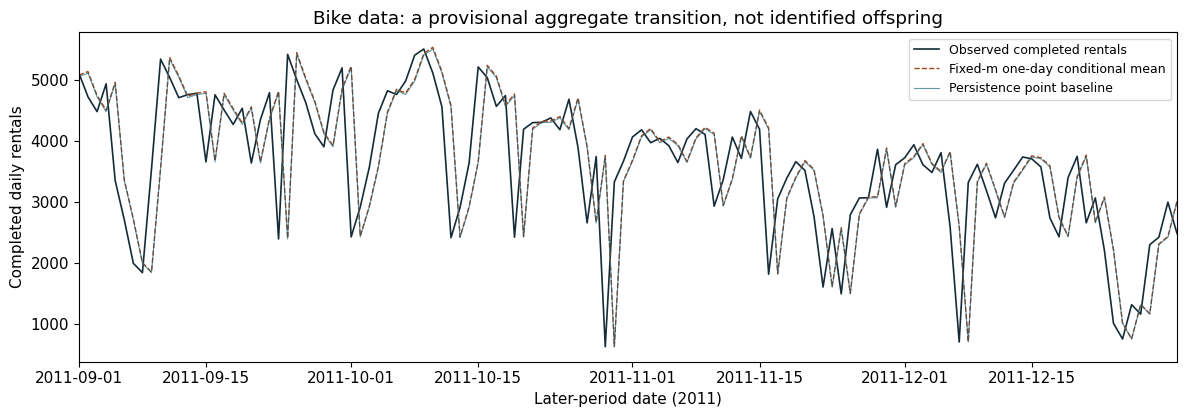

In [18]:
fig, ax = plt.subplots(figsize=(12, 4.3))
ax.plot(later["dteday"], actual, color="#152c38", lw=1.2, label="Observed completed rentals")
ax.plot(later["dteday"], branch_prediction, color="#a0471c", lw=1, ls="--", label="Fixed-m one-day conditional mean")
ax.plot(later["dteday"], persistence_prediction, color="#155e75", lw=0.8, alpha=0.65, label="Persistence point baseline")
ax.set(xlabel="Later-period date (2011)", ylabel="Completed daily rentals",
       title="Bike data: a provisional aggregate transition, not identified offspring", xlim=(later["dteday"].min(), later["dteday"].max()))
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

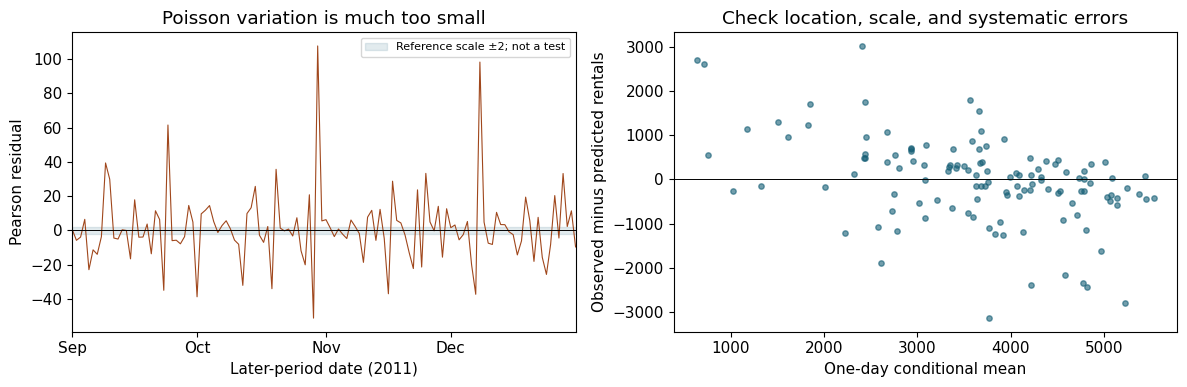

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(later["dteday"], pearson, color="#a0471c", lw=0.8)
axes[0].axhline(0, color="black", lw=0.7)
axes[0].axhspan(-2, 2, color="#155e75", alpha=0.12, label="Reference scale ±2; not a test")
axes[0].set(xlabel="Later-period date (2011)", ylabel="Pearson residual", title="Poisson variation is much too small", xlim=(later["dteday"].min(), later["dteday"].max()))
axes[0].xaxis.set_major_locator(mdates.MonthLocator())
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
axes[0].legend(fontsize=8)
axes[1].scatter(branch_prediction, actual-branch_prediction, s=15, alpha=0.6, color="#155e75")
axes[1].axhline(0, color="black", lw=0.7)
axes[1].set(xlabel="One-day conditional mean", ylabel="Observed minus predicted rentals",
            title="Check location, scale, and systematic errors")
fig.tight_layout()
plt.show()

The later mean squared Pearson residual is about **440.345**, far above the unit benchmark. The provisional branching mean has MAE about **698.773** and RMSE **985.526**; persistence gives **697.418** and **982.418**. Its small upward growth factor offers no improvement on these point scores and its conditional Poisson variance is far too small for the observed errors.

These diagnostics challenge the model; they do not identify a unique cause. Calendar effects, weather, service operations, changing use, or other dependencies need substantive investigation. The daily-rental records alone do not justify forecasts of population extinction, identify a bike reproduction number, or turn a day with zero completed rentals into an absorbing future. Do not transfer the synthetic offspring posterior to these counts.

## 5. Verify computation and audit AI claims
Check theory with independent simulation and mathematical edge cases. Exact expectation and finite-horizon extinction are known here; seeded agreement is evidence about implementation, not proof that the assumptions fit real observations.

This intentionally flawed pseudocode changes both the simulator and the quantity being reported:

```python
m = all_daily_counts[1:].sum() / all_daily_counts[:-1].sum()
for n in range(H):
    population = min(rng.poisson(m * population), 100)
mean_population = samples[samples > 0].mean()
print("Every path alive at H survives forever")
```

Identify the population cap, removal of extinct paths, use of later outcomes in fitting, and the infinite-horizon claim. If AI assists, ask it to state the units, assumptions, fitting boundary, and independent verification checks. Cite your checks and disclose assistance; fluency is not validation.

In [20]:
assert np.array_equal(paths, simulate_branching(M, Z0, H, REPLICAS, SEED))
assert np.all(simulate_branching(0, 3, 5, 100, SEED)[:, 1:] == 0)
assert np.isclose(extinction_by(M, 1), np.exp(-M))
assert np.isclose(extinction_by(M, H, 3), extinction_by(M, H)**3)
assert eventual_extinction(0.8) == 1 and eventual_extinction(1) == 1
q_super = eventual_extinction(1.2)
assert 0 < q_super < 1 and np.isclose(q_super, np.exp(1.2*(q_super-1)))
critical_means, critical_variances = branching_moments(1, 3, 30)
assert np.all(critical_means == 3) and np.array_equal(critical_variances, 3*np.arange(31))
assert np.all(simulate_branching(1.2, 0, 5, 100, SEED) == 0)
print("Passed absorbing-zero, seeded reproducibility, one-generation PGF, ancestral-line,")
print("fixed-point, and critical exact-moment checks. No simulation paths were capped or removed.")

Passed absorbing-zero, seeded reproducibility, one-generation PGF, ancestral-line,
fixed-point, and critical exact-moment checks. No simulation paths were capped or removed.


## 6. Exercises — four short investigations
Submit the four answers below together with Module 5 as Concept Lab 3. For the sustained project, add one concise modeling decision: does its measured unit have a defensible parent–offspring interpretation, or is another process family needed? Do not launch a separate project.

### Exercise 1 — Compare the three regimes
Use Poisson offspring means **0.8, 1.0, and 1.2**, with $Z_0=1$, $H=30$, and 2,000 replicas per case. Compare empirical means and extinction fractions with $m^{30}$ and $q_{30}$. Report an MCSE for each estimate. Explain why the critical model has constant expectation despite eventual extinction, and contrast it with deterministic one-offspring reproduction. Distinguish extinction by 30 from eventual extinction.

In [21]:
# YOUR WORK — Exercise 1
# Add computations, a small comparison table, and your interpretation here.

### Exercise 2 — Ancestors and selection of survivors
Use **$m=1.2$, $Z_0=3$, and $H=20$**. Verify $P(Z_{20}=0)=q_{20}^3$ against simulation at **500 and 2,000 replicas**. Compare the mean over all replicas with the mean among survivors and derive their relationship using $P(Z_{20}>0)$. Explain what increases the accuracy of each estimate and why a population cap or removal of zeros changes the answer. Do not treat alive-at-20 as immortal.

In [22]:
# YOUR WORK — Exercise 2
# Add independent-replica comparisons and the conditional/unconditional distinction here.

### Exercise 3 — Uncertain reproduction and nonlinear prediction
Keep the **synthetic 20-parent sample and Gamma(2, rate 2) prior**, but predict from **three ancestors at $H=30$**. Estimate $E[q_{30}(m)^3\mid x]$ and $E[q(m)^3\mid x]$ using independent posterior draws, with MCSEs. Compare each with its posterior-mean plug-in and with the incorrect $(E[q_{30}(m)\mid x])^3$. Explain why a shared $m$ stays fixed throughout a predictive path and why MCSE, parameter uncertainty, and process randomness answer different questions.

In [23]:
# YOUR WORK — Exercise 3
# Add integrated predictions, numerical-error estimates, and modeling explanations here.

### Exercise 4 — Challenge a bike interpretation and an AI answer
Reproduce the **January–August-only** aggregate estimate and the later one-step MAE/RMSE comparison with persistence. Inspect Pearson residuals and explain why the daily counts do not identify offspring. Audit and repair the pseudocode above: address capping, removing extinct paths, fitting on later outcomes, and claiming eventual survival from a finite run. Give at least two discriminating verification checks and state what additional observations or mechanism would be needed for a branching interpretation. AI use is optional; disclose any assistance and how you checked it.

In [24]:
# YOUR WORK — Exercise 4
# Add the diagnostic audit, repaired reasoning/code, and evidence requirements here.

## Reproducibility and next step
The browser lesson and NumPy use different pseudorandom generators, so individual simulated paths need not match. Compare exact formulas, Monte Carlo uncertainty, and the observed-data calculations. The six figures above are generated from the visible code and saved with the executed notebook.

Module 7 will introduce point-process counts and event times. Keep model choice connected to what is observed: family trees, aggregate counts, and event times encode different information.

In [25]:
print("Python:", platform.python_version())
print({name: metadata.version(name) for name in ["numpy", "pandas", "scipy", "matplotlib"]})
print("Seed:", SEED, "| default m, Z0, H, replicas:", M, Z0, H, REPLICAS)
print("Synthetic posterior: Gamma(shape=24, rate=22); direct draws:", POST_DRAWS)
print("Data SHA-256:", hashlib.sha256(csv_path.read_bytes()).hexdigest())
print("Training: Jan–Aug, 242 pairs; development: Sep–Dec, 122 rolling one-step scores.")

Python: 3.10.9
{'numpy': '1.24.2', 'pandas': '2.0.0', 'scipy': '1.10.1', 'matplotlib': '3.7.1'}
Seed: 6231 | default m, Z0, H, replicas: 1.2 1 20 2000
Synthetic posterior: Gamma(shape=24, rate=22); direct draws: 20000
Data SHA-256: fb9790e24f07b237431b89c787a24ed8e97c365437a86f7161269df9452b2329
Training: Jan–Aug, 242 pairs; development: Sep–Dec, 122 rolling one-step scores.
